## 1. Install packages
Run once, then restart the kernel. Installation requires internet.

In [1]:
%pip install "numpy>=1.26,<3" "pandas>=2.1,<4" "scikit-learn>=1.6,<1.8" matplotlib seaborn joblib

Note: you may need to restart the kernel to use updated packages.


## 2. Imports and settings

In [2]:
from pathlib import Path
import json, re, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.semi_supervised import SelfTrainingClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support, classification_report, confusion_matrix

SEED = 42
MAX_REPORTS = 12000  # Set None for all cleaned reports; requires more time/memory.
LABELED_FRACTION = 0.20
BASE_DIR = Path(r"C:\Users\DELL\Desktop\Sain Bux")
MODEL_DIR = BASE_DIR / 'models'
RESULT_DIR = BASE_DIR / 'results'
MODEL_DIR.mkdir(exist_ok=True)
RESULT_DIR.mkdir(exist_ok=True)
CLASS_CODES = np.array([0, 1, 2, 3, 4])
print('Python:', sys.version.split()[0], '| scikit-learn:', sklearn.__version__)
print('Data folder:', BASE_DIR)

Python: 3.13.9 | scikit-learn: 1.7.2
Data folder: C:\Users\DELL\Desktop\Sain Bux


## 3. Load and inspect the actual CSV files

In [3]:
train_raw = pd.read_csv(BASE_DIR / 'train.csv')
competition_raw = pd.read_csv(BASE_DIR / 'test.csv')
print('Train:', train_raw.shape, '| Competition test:', competition_raw.shape)
print('Columns:', train_raw.columns.tolist())
display(train_raw.head())
display(train_raw.isna().sum().to_frame('Missing values'))
display(train_raw['Priority'].value_counts().sort_index())

Train: (52994, 7) | Competition test: (1328, 6)
Columns: ['Issue_id', 'Component', 'Title', 'Description', 'Status', 'Resolution', 'Priority']


,Issue_id,Component,Title,Description,Status,Resolution,Priority
0,1700,Layout,font size 9px rounded down to 8px {font} {ll},There is a piece of code in the Windows GFX th...,VERIFIED,FIXED,0
1,7991,Plug-ins,Land OOP plugins in mozilla-central (preffed off),We need to land OOP plugins in mozilla-central...,RESOLVED,FIXED,0
2,1150,XPCOM,XP-COM Proxy code crashes when trying to AutoP...,(This bug imported from BugSplat; Netscapes in...,VERIFIED,FIXED,0
3,6143,XUL,crash setting display:none on grid rows [@ nsG...,User-Agent: Mozilla/5.0 (Windows; U; Win...,VERIFIED,FIXED,0
4,5952,Networking: Cache,limit the memory cache to a reasonable value,I have 1GB of RAM; so Im using 31MB of memory ...,VERIFIED,FIXED,0


,Missing values
Issue_id,0
Component,0
Title,0
Description,392
Status,0
Resolution,0
Priority,0


Priority
0     8943
1     9412
2    31154
3     2287
4     1198
Name: count, dtype: int64

## 4. Preprocess text and remove exact duplicates
Use Title and Description only. Status and Resolution can contain information updated after triage. Near-duplicates may remain; mention this limitation.

In [4]:
def clean_text(value):
    if pd.isna(value): return ''
    text = str(value).lower()
    text = re.sub(r'https?://\S+|www\.\S+', ' urltoken ', text)
    return re.sub(r'\s+', ' ', text).strip()

def prepare_reports(frame):
    missing = {'Issue_id', 'Title', 'Description'} - set(frame.columns)
    if missing: raise ValueError(f'Missing columns: {sorted(missing)}')
    result = frame.copy()
    for col in ['Title', 'Description']:
        result[col] = result[col].fillna('').astype(str)
    result['text'] = (result.Title.map(clean_text) + ' ' + result.Description.map(clean_text)).str.strip()
    return result

data = prepare_reports(train_raw)
competition_data = prepare_reports(competition_raw)
data['Priority'] = pd.to_numeric(data['Priority'], errors='raise')
if not data.Priority.isin(CLASS_CODES).all(): raise ValueError('Unexpected priority codes.')
data['Priority'] = data.Priority.astype(int)
before = len(data)
data = data[data.text.ne('')].drop_duplicates('Issue_id').drop_duplicates('text').reset_index(drop=True)
print('Before:', before, '| After cleaning:', len(data), '| Removed:', before-len(data))
display(data[['Issue_id','Title','Priority','text']].head())

Before: 52994 | After cleaning: 52763 | Removed: 231


,Issue_id,Title,Priority,text
0,1700,font size 9px rounded down to 8px {font} {ll},0,font size 9px rounded down to 8px {font} {ll} ...
1,7991,Land OOP plugins in mozilla-central (preffed off),0,land oop plugins in mozilla-central (preffed o...
2,1150,XP-COM Proxy code crashes when trying to AutoP...,0,xp-com proxy code crashes when trying to autop...
3,6143,crash setting display:none on grid rows [@ nsG...,0,crash setting display:none on grid rows [@ nsg...
4,5952,limit the memory cache to a reasonable value,0,limit the memory cache to a reasonable value i...


## 5. Inspect class imbalance

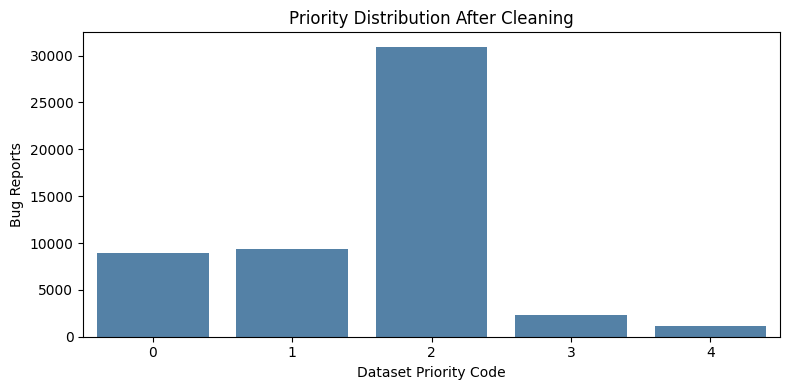

In [5]:
counts = data.Priority.value_counts().sort_index()
plt.figure(figsize=(8,4))
sns.barplot(x=counts.index.astype(str), y=counts.values, color='steelblue')
plt.title('Priority Distribution After Cleaning')
plt.xlabel('Dataset Priority Code'); plt.ylabel('Bug Reports')
plt.tight_layout()
plt.savefig(RESULT_DIR/'priority_distribution.png', dpi=150)
plt.show()

## 6. Create separate training / validation / final evaluation sets
Overall proportions: 60% / 20% / 20%. Final evaluation does not select thresholds.

In [6]:
if MAX_REPORTS is not None and len(data)>MAX_REPORTS:
    working_data, _ = train_test_split(data, train_size=MAX_REPORTS, stratify=data.Priority, random_state=SEED)
else:
    working_data = data.copy()
working_data = working_data.reset_index(drop=True)
development, evaluation_data = train_test_split(working_data, test_size=0.20, stratify=working_data.Priority, random_state=SEED)
training_pool, validation_data = train_test_split(development, test_size=0.25, stratify=development.Priority, random_state=SEED)
training_pool = training_pool.reset_index(drop=True)
validation_data = validation_data.reset_index(drop=True)
evaluation_data = evaluation_data.reset_index(drop=True)
assert set(training_pool.text).isdisjoint(validation_data.text)
assert set(training_pool.text).isdisjoint(evaluation_data.text)
assert set(validation_data.text).isdisjoint(evaluation_data.text)
print('Training:',len(training_pool),'Validation:',len(validation_data),'Evaluation:',len(evaluation_data))
splits = pd.concat([
    training_pool[['Issue_id']].assign(split='training'),
    validation_data[['Issue_id']].assign(split='validation'),
    evaluation_data[['Issue_id']].assign(split='evaluation')
])
splits.to_csv(RESULT_DIR/'split_assignments.csv', index=False)

Training: 7200 Validation: 2400 Evaluation: 2400


## 7. Hide 80% of training labels
Unknown labels are represented by -1. Hidden true labels are not passed to either training model. Stratified seed sampling uses original labels to construct this simulated experiment.

In [7]:
indices = np.arange(len(training_pool))
labeled_indices, unlabeled_indices = train_test_split(indices, train_size=LABELED_FRACTION, stratify=training_pool.Priority, random_state=SEED)
y_semi = np.full(len(training_pool), -1, dtype=int)
y_semi[labeled_indices] = training_pool.loc[labeled_indices,'Priority'].to_numpy()
labeled_mask = y_semi != -1
print('Visible labels:',labeled_mask.sum(),'Unlabeled:',(~labeled_mask).sum())
display(pd.Series(y_semi[labeled_mask]).value_counts().sort_index())
few_labels = training_pool[['Issue_id','Title','Description']].copy()
few_labels['Priority'] = pd.Series(y_semi,dtype='Int64').mask(y_semi==-1)
few_labels.to_csv(RESULT_DIR/'few_label_training.csv',index=False)

Visible labels: 1440 Unlabeled: 5760


0    244
1    256
2    845
3     62
4     33
Name: count, dtype: int64

## 8. TF-IDF features
Fit vocabulary on the training pool only, including its unlabeled texts. Validation/evaluation use transform only.

In [8]:
vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1,2), min_df=2, max_df=0.98, sublinear_tf=True, strip_accents='unicode', dtype=np.float32)
X_train = vectorizer.fit_transform(training_pool.text)
X_validation = vectorizer.transform(validation_data.text)
X_evaluation = vectorizer.transform(evaluation_data.text)
y_validation = validation_data.Priority.to_numpy()
y_evaluation = evaluation_data.Priority.to_numpy()
print('Training features:',X_train.shape)

Training features: (7200, 5000)


## 9. Labeled-only Random Forest baseline
Both methods use exactly the same known seed labels and feature representation.

In [18]:
from sklearn.metrics import recall_score

configurations = [
    {
        "name": "balanced_leaf2",
        "max_depth": None,
        "min_samples_leaf": 2,
        "max_features": "sqrt",
        "bootstrap": True
    },
    {
        "name": "balanced_leaf5",
        "max_depth": None,
        "min_samples_leaf": 5,
        "max_features": "sqrt",
        "bootstrap": True
    },
    {
        "name": "balanced_depth30",
        "max_depth": 30,
        "min_samples_leaf": 3,
        "max_features": 0.10,
        "bootstrap": True
    },
    {
        "name": "balanced_no_bootstrap",
        "max_depth": None,
        "min_samples_leaf": 3,
        "max_features": 0.10,
        "bootstrap": False
    }
]

rf_results = []

baseline = None
selected_rf_parameters = None
best_rf_validation_f1 = -1

for config in configurations:
    parameters = {
        key: value
        for key, value in config.items()
        if key != "name"
    }

    candidate = RandomForestClassifier(
        n_estimators=150,
        criterion="entropy",
        class_weight="balanced",
        random_state=SEED,
        n_jobs=-1,
        **parameters
    )

    print("Training:", config["name"], flush=True)

    candidate.fit(
        X_train[labeled_mask],
        y_semi[labeled_mask]
    )

    prediction = candidate.predict(X_validation)

    macro_f1 = f1_score(
        y_validation,
        prediction,
        labels=CLASS_CODES,
        average="macro",
        zero_division=0
    )

    macro_recall = recall_score(
        y_validation,
        prediction,
        labels=CLASS_CODES,
        average="macro",
        zero_division=0
    )

    rf_results.append({
        "configuration": config["name"],
        "validation_accuracy": accuracy_score(
            y_validation, prediction
        ),
        "validation_macro_f1": macro_f1,
        "validation_macro_recall": macro_recall
    })

    if macro_f1 > best_rf_validation_f1:
        baseline = candidate
        selected_rf_parameters = parameters.copy()
        best_rf_validation_f1 = macro_f1

rf_results_df = pd.DataFrame(rf_results)

display(
    rf_results_df.sort_values(
        "validation_macro_f1",
        ascending=False
    )
)

rf_results_df.to_csv(
    RESULT_DIR / "random_forest_validation_search.csv",
    index=False
)

print("\nSelected parameters:", selected_rf_parameters)
print("Best validation macro F1:", best_rf_validation_f1)

# Cell 10 will use the selected Random Forest settings.
def make_random_forest():
    return RandomForestClassifier(
        n_estimators=150,
        criterion="entropy",
        class_weight="balanced",
        random_state=SEED,
        n_jobs=-1,
        **selected_rf_parameters
    )

Training: balanced_leaf2
Training: balanced_leaf5
Training: balanced_depth30
Training: balanced_no_bootstrap


,configuration,validation_accuracy,validation_macro_f1,validation_macro_recall
1,balanced_leaf5,0.566667,0.263580,0.263810
2,balanced_depth30,0.595000,0.226892,0.238252
3,balanced_no_bootstrap,0.586667,0.226805,0.237471
0,balanced_leaf2,0.602083,0.218024,0.234701



Selected parameters: {'max_depth': None, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'bootstrap': True}
Best validation macro F1: 0.26358028622185864


## 10. Self-Training + Random Forest
This can take several minutes. Select confidence threshold using validation macro F1, not final evaluation. Forest probabilities are not calibrated guarantees. Improvement is not guaranteed.

In [20]:
candidate_thresholds = [0.45, 0.55, 0.65]

validation_results = []

best_model = None
best_threshold = None
best_validation_f1 = -1

for threshold in candidate_thresholds:
    print(
        f"\nSelf-training threshold: {threshold}",
        flush=True
    )

    candidate = SelfTrainingClassifier(
        estimator=make_random_forest(),
        criterion="threshold",
        threshold=threshold,
        max_iter=5
    )

    candidate.fit(X_train, y_semi)

    prediction = candidate.predict(X_validation)

    macro_f1 = f1_score(
        y_validation,
        prediction,
        labels=CLASS_CODES,
        average="macro",
        zero_division=0
    )

    accepted_mask = (
        (y_semi == -1)
        & (candidate.transduction_ != -1)
    )

    pseudo_counts = {
        f"pseudo_code_{int(code)}": int(
            np.sum(
                accepted_mask
                & (candidate.transduction_ == code)
            )
        )
        for code in CLASS_CODES
    }

    validation_results.append({
        "threshold": threshold,
        "validation_macro_f1": macro_f1,
        "accepted_pseudo_labels": int(
            accepted_mask.sum()
        ),
        "iterations": int(candidate.n_iter_),
        "stop_reason": candidate.termination_condition_,
        **pseudo_counts
    })

    print(
        "Validation macro F1:",
        round(macro_f1, 4),
        "| Accepted pseudo-labels:",
        int(accepted_mask.sum()),
        flush=True
    )

    if macro_f1 > best_validation_f1:
        best_model = candidate
        best_threshold = threshold
        best_validation_f1 = macro_f1

validation_results_df = pd.DataFrame(validation_results)

display(validation_results_df)

validation_results_df.to_csv(
    RESULT_DIR / "validation_threshold_results.csv",
    index=False
)

print("\nSelected threshold:", best_threshold)
print("Baseline validation macro F1:", best_rf_validation_f1)
print("Self-training validation macro F1:", best_validation_f1)

print("\nSelected model: per-class validation performance")

print(
    classification_report(
        y_validation,
        best_model.predict(X_validation),
        labels=CLASS_CODES,
        target_names=[
            f"Priority code {code}"
            for code in CLASS_CODES
        ],
        zero_division=0
    )
)


Self-training threshold: 0.45
Validation macro F1: 0.2241 | Accepted pseudo-labels: 542

Self-training threshold: 0.55
Validation macro F1: 0.2636 | Accepted pseudo-labels: 0

Self-training threshold: 0.65
Validation macro F1: 0.2636 | Accepted pseudo-labels: 0


,threshold,validation_macro_f1,accepted_pseudo_labels,iterations,stop_reason,pseudo_code_0,pseudo_code_1,pseudo_code_2,pseudo_code_3,pseudo_code_4
0,0.45,0.224141,542,5,max_iter,164,0,378,0,0
1,0.55,0.263580,0,1,no_change,0,0,0,0,0
2,0.65,0.263580,0,1,no_change,0,0,0,0,0



Selected threshold: 0.55
Baseline validation macro F1: 0.26358028622185864
Self-training validation macro F1: 0.26358028622185864

Selected model: per-class validation performance
                 precision    recall  f1-score   support

Priority code 0       0.35      0.26      0.30       407
Priority code 1       0.29      0.16      0.21       428
Priority code 2       0.66      0.84      0.74      1407
Priority code 3       0.10      0.06      0.07       104
Priority code 4       0.00      0.00      0.00        54

       accuracy                           0.57      2400
      macro avg       0.28      0.26      0.26      2400
   weighted avg       0.50      0.57      0.52      2400



In [21]:
# Active self-training experiment:
# selected to demonstrate learning from unlabeled reports.
# The labeled-only baseline has a higher validation macro F1.

best_threshold = 0.45

best_model = SelfTrainingClassifier(
    estimator=make_random_forest(),
    criterion="threshold",
    threshold=best_threshold,
    max_iter=5
)

best_model.fit(X_train, y_semi)

best_validation_f1 = f1_score(
    y_validation,
    best_model.predict(X_validation),
    labels=CLASS_CODES,
    average="macro",
    zero_division=0
)

accepted = int(
    np.sum(
        (y_semi == -1)
        & (best_model.transduction_ != -1)
    )
)

print("Active self-training threshold:", best_threshold)
print("Accepted pseudo-labels:", accepted)
print("Validation macro F1:", best_validation_f1)
print("Baseline validation macro F1:", best_rf_validation_f1)

Active self-training threshold: 0.45
Accepted pseudo-labels: 542
Validation macro F1: 0.22414123077617934
Baseline validation macro F1: 0.26358028622185864


## 11. Learning iterations and label audit

,iteration,new_pseudo_labels
0,1,11
1,2,20
2,3,66
3,4,203
4,5,242


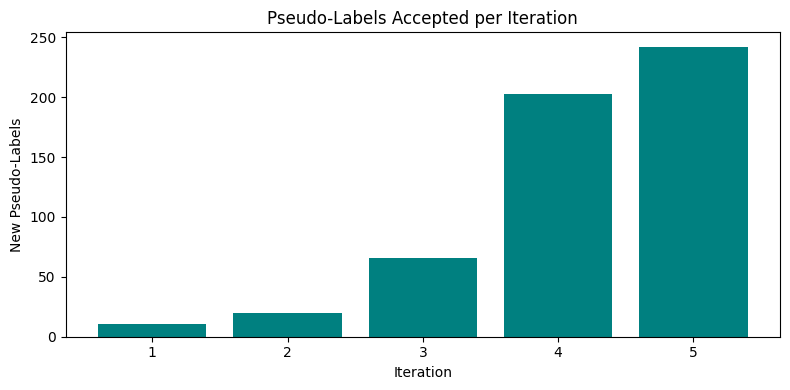

,Issue_id,Title,seed_priority,assigned_priority,label_source,iteration_added
0,11225,Pages w/a DOCTYPE are blank...?,<NA>,<NA>,still_unlabeled,-1
1,4190,Font attributes disappear when you double clic...,<NA>,<NA>,still_unlabeled,-1
2,51847,http 0.9 rendered as content-type: text/plain,<NA>,<NA>,still_unlabeled,-1
3,29886,document.onclick shows links from other window,<NA>,<NA>,still_unlabeled,-1
4,38815,Blinking duplicate textfields in the wrong place,2,2,seed_label,0
5,5551,[FIX]Non-displayed invalid frames processed - ...,<NA>,<NA>,still_unlabeled,-1
6,6620,[FIX]Crash [@ nsMathMLContainerFrame::FixInter...,<NA>,0,pseudo_label,5
7,21405,image fails to paint when loaded in frameset d...,<NA>,<NA>,still_unlabeled,-1
8,25198,[gfx] nsDeviceContextWin::GetClientRect is broken,<NA>,<NA>,still_unlabeled,-1
9,19401,Compare does not lazy load (1GEPO80),<NA>,<NA>,still_unlabeled,-1


label_source
still_unlabeled    5218
seed_label         1440
pseudo_label        542
Name: count, dtype: int64

In [22]:
history_df=pd.DataFrame([dict(iteration=i,new_pseudo_labels=int(np.sum(best_model.labeled_iter_==i))) for i in range(1,best_model.n_iter_+1)])
display(history_df)
history_df.to_csv(RESULT_DIR/'self_training_history.csv',index=False)
plt.figure(figsize=(8,4))
plt.bar(history_df.iteration,history_df.new_pseudo_labels,color='teal')
plt.title('Pseudo-Labels Accepted per Iteration')
plt.xlabel('Iteration'); plt.ylabel('New Pseudo-Labels')
plt.xticks(history_df.iteration); plt.tight_layout()
plt.savefig(RESULT_DIR/'self_training_history.png',dpi=150)
plt.show()
audit=training_pool[['Issue_id','Title']].copy()
audit['seed_priority']=pd.Series(y_semi,dtype='Int64').mask(y_semi==-1)
audit['assigned_priority']=pd.Series(best_model.transduction_,dtype='Int64').mask(best_model.transduction_==-1)
audit['label_source']=np.where(y_semi!=-1,'seed_label',np.where(best_model.transduction_!=-1,'pseudo_label','still_unlabeled'))
audit['iteration_added']=best_model.labeled_iter_
audit.to_csv(RESULT_DIR/'training_label_audit.csv',index=False)
display(audit.head(15))
display(audit.label_source.value_counts())

## 12. Final evaluation
Use once after fixing settings. Repeatedly tuning against these results turns this portion into validation data.

In [23]:
def calculate_metrics(truth,predictions):
    precision,recall,macro_f1,_=precision_recall_fscore_support(truth,predictions,labels=CLASS_CODES,average='macro',zero_division=0)
    return dict(accuracy=float(accuracy_score(truth,predictions)),macro_precision=float(precision),macro_recall=float(recall),macro_f1=float(macro_f1),weighted_f1=float(f1_score(truth,predictions,labels=CLASS_CODES,average='weighted',zero_division=0)))

baseline_predictions=baseline.predict(X_evaluation)
semi_predictions=best_model.predict(X_evaluation)
comparison=pd.DataFrame([
    dict(method='Labeled-only Random Forest',**calculate_metrics(y_evaluation,baseline_predictions)),
    dict(method='Self-Training + Random Forest',**calculate_metrics(y_evaluation,semi_predictions))
])
display(comparison.round(4))
comparison.to_csv(RESULT_DIR/'final_model_comparison.csv',index=False)
names=[f'Priority code {i}' for i in CLASS_CODES]
print(classification_report(y_evaluation,semi_predictions,labels=CLASS_CODES,target_names=names,zero_division=0))
report_dictionary=classification_report(y_evaluation,semi_predictions,labels=CLASS_CODES,target_names=names,output_dict=True,zero_division=0)
(RESULT_DIR/'classification_report.json').write_text(json.dumps(report_dictionary,indent=2),encoding='utf-8')
evaluation_predictions=evaluation_data[['Issue_id','Title','Priority']].copy()
evaluation_predictions['baseline_prediction']=baseline_predictions
evaluation_predictions['self_training_prediction']=semi_predictions
evaluation_predictions.to_csv(RESULT_DIR/'evaluation_predictions.csv',index=False)

,method,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
0,Labeled-only Random Forest,0.5754,0.3697,0.2757,0.2828,0.5295
1,Self-Training + Random Forest,0.4471,0.3404,0.2764,0.2695,0.4638


                 precision    recall  f1-score   support

Priority code 0       0.33      0.34      0.33       407
Priority code 1       0.21      0.44      0.29       428
Priority code 2       0.70      0.53      0.60      1407
Priority code 3       0.13      0.04      0.06       104
Priority code 4       0.33      0.04      0.07        54

       accuracy                           0.45      2400
      macro avg       0.34      0.28      0.27      2400
   weighted avg       0.52      0.45      0.46      2400



## 13. Confusion matrices and comparison chart

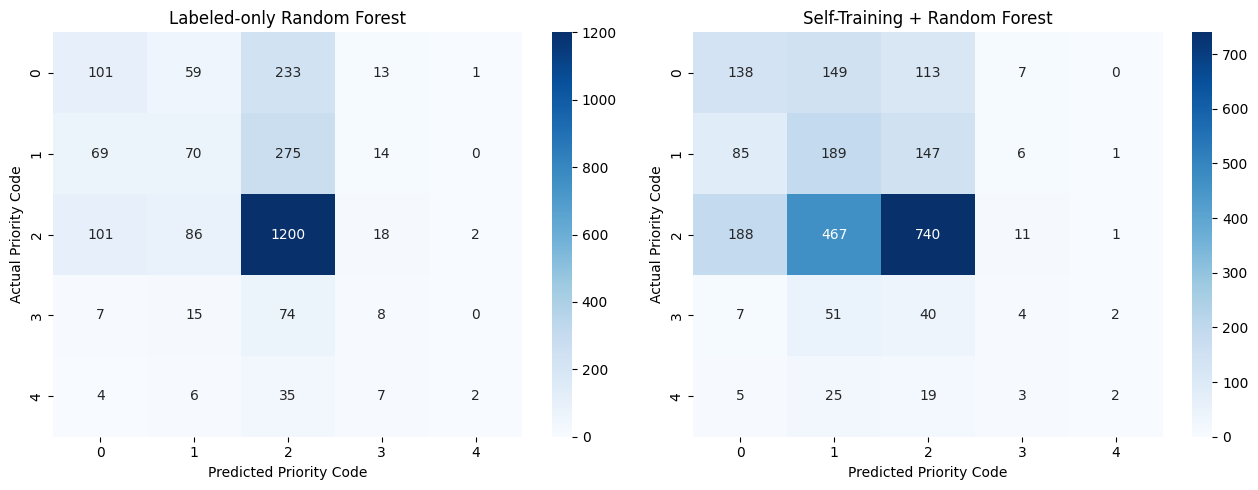

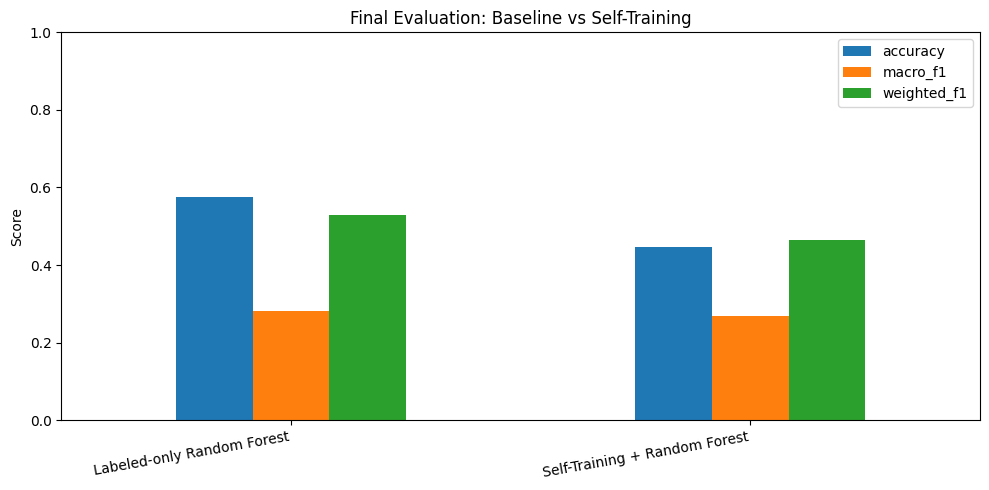

In [24]:
fig,axes=plt.subplots(1,2,figsize=(13,5))
for axis,predictions,title in [(axes[0],baseline_predictions,'Labeled-only Random Forest'),(axes[1],semi_predictions,'Self-Training + Random Forest')]:
    matrix=confusion_matrix(y_evaluation,predictions,labels=CLASS_CODES)
    sns.heatmap(matrix,annot=True,fmt='d',cmap='Blues',xticklabels=CLASS_CODES,yticklabels=CLASS_CODES,ax=axis)
    axis.set_title(title); axis.set_xlabel('Predicted Priority Code'); axis.set_ylabel('Actual Priority Code')
plt.tight_layout(); plt.savefig(RESULT_DIR/'confusion_matrices.png',dpi=150); plt.show()
comparison.set_index('method')[['accuracy','macro_f1','weighted_f1']].plot(kind='bar',figsize=(10,5),ylim=(0,1))
plt.title('Final Evaluation: Baseline vs Self-Training'); plt.ylabel('Score'); plt.xlabel('')
plt.xticks(rotation=10,ha='right'); plt.tight_layout()
plt.savefig(RESULT_DIR/'model_comparison.png',dpi=150); plt.show()

## 14. Predict a new bug
Original dataset codes are retained. Model confidence is not measured accuracy. Human triage is still needed.

In [25]:
def predict_bug(title,description):
    text=clean_text(f"{'' if title is None else title} {'' if description is None else description}")
    if not text: raise ValueError('Provide a title or description.')
    features=vectorizer.transform([text])
    if features.nnz==0:
        return dict(predicted_priority_code=None,model_confidence=None,message='No recognized vocabulary; manual review required.')
    probabilities=best_model.predict_proba(features)[0]
    position=int(np.argmax(probabilities))
    return dict(predicted_priority_code=int(best_model.classes_[position]),model_confidence=float(probabilities[position]),class_probabilities={str(int(c)):float(p) for c,p in zip(best_model.classes_,probabilities)},message='Human review recommended; confidence is not accuracy.')

display(predict_bug('Application crashes when opening a new tab','The browser closes unexpectedly whenever a new tab is opened after an update.'))

{'predicted_priority_code': 0,
 'model_confidence': 0.3476540428191358,
 'class_probabilities': {'0': 0.3476540428191358,
  '1': 0.288338905676819,
  '2': 0.2595230674806496,
  '3': 0.07559190497497591,
  '4': 0.028892079048419693},
 'message': 'Human review recommended; confidence is not accuracy.'}

## 15. Predict the supplied Kaggle test file
No true priorities exist in this file, so no accuracy is calculated. Export is for local analysis, not a verified competition submission schema.

In [26]:
X_competition=vectorizer.transform(competition_data.text)
probabilities=best_model.predict_proba(X_competition)
competition_output=competition_data[['Issue_id','Title']].copy()
competition_output['Predicted_Priority']=best_model.classes_[probabilities.argmax(axis=1)].astype(int)
competition_output['Model_Confidence']=probabilities.max(axis=1)
competition_output['Recognized_Vocabulary']=np.asarray(X_competition.getnnz(axis=1))>0
competition_output['Needs_Review']=(~competition_output.Recognized_Vocabulary)|(competition_output.Model_Confidence<0.60)
competition_output['Exact_Training_Text_Match']=competition_data.text.isin(set(training_pool.text))
competition_output.to_csv(RESULT_DIR/'kaggle_test_predictions.csv',index=False)
display(competition_output.head(10))
print('Saved predictions:',len(competition_output))
print('Exact training-text matches:',int(competition_output.Exact_Training_Text_Match.sum()))

,Issue_id,Title,Predicted_Priority,Model_Confidence,Recognized_Vocabulary,Needs_Review,Exact_Training_Text_Match
0,6578,Finalize yield syntax to match ES4/JS2 proposal,1,0.273606,True,True,False
1,8050,e10s HTTP: offline application cache,2,0.260806,True,True,False
2,5281,[FIX]Add GetOwnerDocument on nsIContent or nsG...,1,0.296169,True,True,False
3,7871,Text editing broken in Firebug edit mode and o...,1,0.310022,True,True,False
4,2411,shockwave movies redraw improperly on mac(nsbe...,2,0.733867,True,False,False
5,2120,Cancelling the file picker causes crash,2,0.308643,True,True,False
6,217,[toolbox] [debugger] sidepanels dont show up a...,2,0.301186,True,True,False
7,8680,WebRTC crash [@ mozilla::NrIceCtx::GetGlobalAt...,0,0.430651,True,True,False
8,5027,Margin value isnt always saved as entered,2,0.331717,True,True,False
9,3583,crashes [@ SECITEM_CompareItem],0,0.785301,True,False,False


Saved predictions: 1328
Exact training-text matches: 5


## 16. Save model, vectorizer and metadata
Only load joblib files you created or trust. Preserve package versions for the later Streamlit app.

In [27]:
joblib.dump(best_model,MODEL_DIR/'self_training_random_forest.joblib')
joblib.dump(vectorizer,MODEL_DIR/'tfidf_vectorizer.joblib')
metadata=dict(project='Bug Report Priority Classifier with Few Labels',student='Sain Bux',learning_type='Semi-Supervised',algorithm='Self-Training + Random Forest',features=['Title','Description'],priority_codes=[int(c) for c in best_model.classes_],priority_name_mapping='Unverified; original dataset codes retained',random_seed=SEED,reports_used=len(working_data),training_reports=len(training_pool),validation_reports=len(validation_data),evaluation_reports=len(evaluation_data),seed_labels=int(labeled_mask.sum()),initially_unlabeled=int((~labeled_mask).sum()),accepted_pseudo_labels=int(np.sum((y_semi==-1)&(best_model.transduction_!=-1))),selected_threshold=float(best_threshold),validation_macro_f1=float(best_validation_f1),sklearn_version=sklearn.__version__,numpy_version=np.__version__,pandas_version=pd.__version__,joblib_version=joblib.__version__,python_version=sys.version.split()[0],experiment='Simulated few-label experiment with separate validation and evaluation')
(MODEL_DIR/'metadata.json').write_text(json.dumps(metadata,indent=2),encoding='utf-8')
print('Saved files:')
for path in sorted(MODEL_DIR.iterdir()): print(path.name)

Saved files:
metadata.json
self_training_random_forest.joblib
tfidf_vectorizer.joblib


## 17. Reload verification

In [28]:
loaded_model=joblib.load(MODEL_DIR/'self_training_random_forest.joblib')
loaded_vectorizer=joblib.load(MODEL_DIR/'tfidf_vectorizer.joblib')
sample=evaluation_data.text.head(10)
assert np.array_equal(best_model.predict(vectorizer.transform(sample)),loaded_model.predict(loaded_vectorizer.transform(sample)))
print('SUCCESS: saved model reloads and predictions match.')
print('Next: share validation_threshold_results.csv and final_model_comparison.csv for the VS Code app stage.')

SUCCESS: saved model reloads and predictions match.
Next: share validation_threshold_results.csv and final_model_comparison.csv for the VS Code app stage.


## Interpretation and references
- Report actual measured scores; do not claim self-training necessarily improves the baseline.
- Hidden labels simulate annotation scarcity; this is not a naturally unlabeled dataset.
- Stratified random splits do not guarantee independence across related issues or projects. Exact duplicates were removed, but near-duplicates and temporal relationships may remain.
- Test results do not establish suitability for automated business triage. Priority requires organizational context.
- Keep original dataset access/redistribution terms in mind before publishing raw files to GitHub.

Sources: [Kaggle dataset](https://www.kaggle.com/competitions/isec-sdc-2025/data), [SelfTrainingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.semi_supervised.SelfTrainingClassifier.html), [RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html).
